# Détection automatique de fissures sur infrastructures routières
## Dataset RDD2022 — Approche MLOps de bout en bout

---

### Contexte et problématique métier

L'inspection des ponts et chaussées est un enjeu majeur de sécurité publique et de maintenance préventive. Les méthodes traditionnelles reposent sur des inspections visuelles humaines, coûteuses, subjectives et difficilement extensibles à grande échelle. L'objectif de ce projet est de concevoir un système automatisé capable de détecter, localiser et classifier les dégradations de surface (fissures longitudinales, transversales, faïençage, nids-de-poule) à partir d'images acquises par des véhicules instrumentés ou des drones.

### Jeu de données retenu

Nous utilisons le **Road Damage Dataset 2022 (RDD2022)**, publié dans le cadre de la compétition *Crowdsensing-based Road Damage Detection Challenge (CRDDC'2022)*. Ce dataset regroupe **47 420 images** issues de six pays (Japon, Inde, République Tchèque, Norvège, États-Unis, Chine), annotées manuellement avec plus de **55 000 instances** de dommages réparties en quatre classes. Les annotations sont fournies au format **Pascal VOC (XML)**, ce qui facilite l'intégration avec les frameworks de détection d'objets standards.

### Démarche et exigences MLOps

Le projet suit une démarche industrialisée structurée en quatre étapes obligatoires :
1. **Data Quality & Linting** — Validation du schéma des données, contrôle de cohérence image/annotation, vérification statique du code (flake8, black).
2. **Train & Versioning** — Entraînement reproductible, suivi des expériences via MLflow, versionnement des données avec DVC.
3. **Evaluate & Test** — Évaluation sur un jeu de test indépendant, génération automatique de rapports de performance.
4. **Deploy** — Conteneurisation de l'API d'inférence (FastAPI) et déploiement automatisé.

### Organisation de cette première phase

Cette phase initiale couvre les aspects **Data Engineering et Data Quality** : configuration de l'environnement reproductible, acquisition et vérification d'intégrité du dataset, audit de la structure des annotations, analyse exploratoire de la distribution des classes, et enfin construction d'un découpage train/validation/test garantissant l'absence de fuite de données. Aucune étape de modélisation n'est abordée ici : la rigueur de cette fondation conditionne directement la fiabilité des résultats ultérieurs.

In [5]:
from google.colab import auth
auth.authenticate_user()

from googleapiclient.discovery import build
import os

service = build('drive', 'v3')

# --- Trouver l'ID du raccourci RDD2022 dans Datasets ---
def trouver_id(nom, parent_nom="Datasets"):
    # Trouver le dossier Datasets
    res = service.files().list(q=f"name='{parent_nom}' and mimeType='application/vnd.google-apps.folder' and trashed=false",
                               fields="files(id, name)").execute()
    if not res['files']:
        return None
    parent_id = res['files'][0]['id']
    # Trouver le raccourci dedans
    res = service.files().list(q=f"name='{nom}' and '{parent_id}' in parents and trashed=false",
                               fields="files(id, name, mimeType, shortcutDetails)").execute()
    return res['files'][0] if res['files'] else None

raccourci = trouver_id("RDD2022")
print("Raccourci trouvé :", raccourci)

Raccourci trouvé : {'mimeType': 'application/vnd.google-apps.shortcut', 'id': '1OfwOoTUxRzCjWhuABgoGCKlW3hupx_Xb', 'name': 'RDD2022', 'shortcutDetails': {'targetId': '12CY5xLHAtg9_4PKj5aVglb8OgEW5r0UW', 'targetMimeType': 'application/vnd.google-apps.folder'}}


In [ ]:
from googleapiclient.discovery import build
from google.colab import auth
auth.authenticate_user()
service = build('drive', 'v3')

# --- ID du dossier cible (racine du partage caillou) ---
SOURCE_ID = "12CY5xLHAtg9_4PKj5aVglb8OgEW5r0UW"

# --- Créer le dossier destination dans ton Drive work ---
dossier_dest = service.files().create(
    body={"name": "RDD2022_local",
          "mimeType": "application/vnd.google-apps.folder",
          "parents": []}   # racine de My Drive
).execute()
DEST_ID = dossier_dest["id"]
print(f"Dossier destination créé : {DEST_ID}")


def copier_recursif(source_id, dest_id):
    """Copie tous les fichiers/dossiers d'un dossier Drive vers un autre."""
    page_token = None
    while True:
        res = service.files().list(
            q=f"'{source_id}' in parents and trashed=false",
            fields="nextPageToken, files(id, name, mimeType, size)",
            pageToken=page_token,
            pageSize=1000
        ).execute()

        for f in res.get("files", []):
            if f["mimeType"] == "application/vnd.google-apps.folder":
                # Créer le sous-dossier côté destination
                sous = service.files().create(
                    body={"name": f["name"],
                          "mimeType": "application/vnd.google-apps.folder",
                          "parents": [dest_id]}
                ).execute()
                print(f"[DIR]  {f['name']}")
                copier_recursif(f["id"], sous["id"])
            else:
                # Copier le fichier
                service.files().copy(
                    fileId=f["id"],
                    body={"name": f["name"], "parents": [dest_id]}
                ).execute()
                taille_mo = int(f.get("size", 0)) / 1e6
                print(f"[FILE] {f['name']}  ({taille_mo:.1f} Mo)")

        page_token = res.get("nextPageToken")
        if not page_token:
            break


print("\nCopie en cours (peut prendre 30-60 min)...")
copier_recursif(SOURCE_ID, DEST_ID)
print("\nCopie terminée.")

Dossier destination créé : 10CZEl7GWQfdsXAH4zFXiXeFUncnYAb3h

Copie en cours (peut prendre 30-60 min)...
[FILE] RDD2022_released_through_CRDDC2022.zip  (13264.2 Mo)

Copie terminée.


In [ ]:
from pathlib import Path
d = Path("/content/drive/MyDrive/RDD2022_local")
print("Contenu :")
for f in d.iterdir():
    taille_go = f.stat().st_size / 1e9 if f.is_file() else 0
    print(f"  {f.name}  ({taille_go:.2f} Go)" if f.is_file() else f"  {f.name}/")

Contenu :
  RDD2022_released_through_CRDDC2022.zip  (13.26 Go)


In [ ]:
from googleapiclient.discovery import build
from google.colab import auth
auth.authenticate_user()
service = build('drive', 'v3')

# --- Trouver l'ID cible du raccourci RDD2022_runs ---
res = service.files().list(
    q="name='RDD2022_runs' and mimeType='application/vnd.google-apps.shortcut' and trashed=false",
    fields="files(id, name, shortcutDetails)"
).execute()

if not res['files']:
    print("Raccourci RDD2022_runs introuvable")
else:
    SOURCE_ID = res['files'][0]['shortcutDetails']['targetId']
    print(f"Source : {SOURCE_ID}")

    # Créer le dossier destination
    dest = service.files().create(
        body={"name": "RDD2022_runs_local",
              "mimeType": "application/vnd.google-apps.folder",
              "parents": []}
    ).execute()
    DEST_ID = dest['id']
    print(f"Destination : {DEST_ID}")

    # Copier récursivement
    def copier(source_id, dest_id):
        page_token = None
        while True:
            r = service.files().list(
                q=f"'{source_id}' in parents and trashed=false",
                fields="nextPageToken, files(id, name, mimeType, size)",
                pageToken=page_token
            ).execute()
            for f in r.get("files", []):
                if f["mimeType"] == "application/vnd.google-apps.folder":
                    s = service.files().create(
                        body={"name": f["name"],
                              "mimeType": "application/vnd.google-apps.folder",
                              "parents": [dest_id]}
                    ).execute()
                    copier(f["id"], s["id"])
                else:
                    service.files().copy(
                        fileId=f["id"],
                        body={"name": f["name"], "parents": [dest_id]}
                    ).execute()
                    print(f"  {f['name']}")
            page_token = r.get("nextPageToken")
            if not page_token:
                break

    print("\nCopie RDD2022_runs...")
    copier(SOURCE_ID, DEST_ID)
    print("Terminé.")

Source : 1jzgQvsTkG2tRcE6oKwmjUTKbo1JPjs48
Destination : 17E6c9CLfgQsLIVzfYUOMUX6Yw1IMye1L

Copie RDD2022_runs...
  results.png
  confusion_matrix.png
  confusion_matrix_normalized.png
  BoxR_curve.png
  BoxP_curve.png
  BoxF1_curve.png
  BoxPR_curve.png
  val_batch2_pred.jpg
  val_batch2_labels.jpg
  val_batch1_pred.jpg
  val_batch1_labels.jpg
  val_batch0_pred.jpg
  val_batch0_labels.jpg
  results.csv
  train_batch17822.jpg
  train_batch17821.jpg
  train_batch17820.jpg
  train_batch2.jpg
  train_batch1.jpg
  train_batch0.jpg
  labels.jpg
  args.yaml
  last.pt
  best.pt
  results.png
  confusion_matrix.png
  confusion_matrix_normalized.png
  BoxR_curve.png
  BoxP_curve.png
  BoxF1_curve.png
  BoxPR_curve.png
  val_batch2_labels.jpg
  val_batch2_pred.jpg
  val_batch1_labels.jpg
  val_batch1_pred.jpg
  val_batch0_labels.jpg
  val_batch0_pred.jpg
  results.csv
  train_batch11882.jpg


TimeoutError: The read operation timed out

In [ ]:
from pathlib import Path

for run in ["yolov8s_baseline", "yolov8s_phaseA_640_25ep"]:
    best = Path(f"/content/drive/MyDrive/RDD2022_runs_local/{run}/weights/best.pt")
    last = Path(f"/content/drive/MyDrive/RDD2022_runs_local/{run}/weights/last.pt")
    print(f"{run} :")
    print(f"  best.pt : {best.exists()}  ({best.stat().st_size / 1e6:.1f} Mo)" if best.exists() else f"  best.pt : absent")
    print(f"  last.pt : {last.exists()}" if last.exists() else f"  last.pt : absent")

yolov8s_baseline :
  best.pt : absent
  last.pt : absent
yolov8s_phaseA_640_25ep :
  best.pt : True  (22.5 Mo)
  last.pt : True


## 1. Configuration de l'environnement

Avant toute manipulation de données, nous établissons un environnement de travail **reproductible et persisté**. Trois choix structurants sont faits ici :

- **Montage de Google Drive** : Colab fournit un espace éphémère. Le Drive sert de stockage persistant pour les données brutes et les artefacts de modèle, évitant tout re-téléchargement coûteux entre sessions.
- **Graine aléatoire fixée** : Toute opération stochastique (mélange, initialisation de poids, split) doit être reproductible. Nous fixons la graine pour `random`, `numpy` — PyTorch sera traité de la même manière en phase d'entraînement.
- **Séparation stricte des chemins** : `RACINE_DRIVE` pour la persistance, `RACINE_LOCALE` pour les traitements à haute fréquence d'I/O (Colab étant plus rapide en local qu'en montage Drive).

Cette cellule ne produit aucun résultat métier, mais conditionne la fiabilité de l'ensemble du pipeline.

In [6]:
import os
import sys
import random
import zipfile
import shutil
import subprocess
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

from google.colab import drive
drive.mount('/content/drive')

# --- Espaces de stockage ---
# DRIVE : persistant, contient le ZIP source
# COLAB : éphémère, reçoit le dataset extrait
RACINE_DRIVE = Path("/content/drive/MyDrive/RDD2022_local")
RACINE_COLAB = Path("/content/datasets/RDD2022")

RACINE_DRIVE.mkdir(parents=True, exist_ok=True)
RACINE_COLAB.mkdir(parents=True, exist_ok=True)

# --- Archive source (dans le Drive) ---
ARCHIVE_SOURCE = RACINE_DRIVE / "RDD2022_released_through_CRDDC2022.zip"

if not ARCHIVE_SOURCE.exists():
    raise FileNotFoundError(f"Archive introuvable : {ARCHIVE_SOURCE}")

taille_go = ARCHIVE_SOURCE.stat().st_size / 1e9

try:
    with zipfile.ZipFile(ARCHIVE_SOURCE) as z:
        nb_elements = len(z.infolist())
except zipfile.BadZipFile:
    raise RuntimeError(f"Archive ZIP corrompue : {ARCHIVE_SOURCE.name}")

# --- Reproductibilité ---
GRAINE = 42
random.seed(GRAINE)
np.random.seed(GRAINE)

print(f"Drive : {RACINE_DRIVE}")
print(f"Colab : {RACINE_COLAB}")
print(f"Archive : {ARCHIVE_SOURCE.name} ({taille_go:.2f} Go, {nb_elements} éléments)")
print(f"Graine : {GRAINE}")

Mounted at /content/drive
Drive : /content/drive/MyDrive/RDD2022_local
Colab : /content/datasets/RDD2022
Archive : RDD2022_released_through_CRDDC2022.zip (13.26 Go, 7 éléments)
Graine : 42


1.bis — Vérification et activation du GPU
## Vérification du GPU

On s'assure que Colab expose bien un GPU et que PyTorch peut l'utiliser.
Sans cette étape, l'entraînement tournerait silencieusement sur CPU.

In [7]:
import torch

# --- 1. Vérifier la disponibilité du GPU ---
if not torch.cuda.is_available():
    raise RuntimeError(
        "Aucun GPU détecté. Dans Colab : Exécution > Modifier le type "
        "d'exécution > Accélérateur matériel > GPU (T4)."
    )

# --- 2. Identifier le GPU et définir le device global ---
DEVICE = torch.device("cuda")
nom_gpu = torch.cuda.get_device_name(0)
memoire_go = torch.cuda.get_device_properties(0).total_memory / 1e9

print(f"GPU détecté : {nom_gpu}")
print(f"Mémoire     : {memoire_go:.1f} Go")
print(f"Device      : {DEVICE}")

# --- 3. Test fonctionnel : opération sur GPU ---
x = torch.randn(1000, 1000, device=DEVICE)
y = torch.randn(1000, 1000, device=DEVICE)
_ = x @ y  # multiplication matricielle sur GPU

print("Test GPU : OK")
print(f"CUDA version  : {torch.version.cuda}")
print(f"PyTorch       : {torch.__version__}")

RuntimeError: Aucun GPU détecté. Dans Colab : Exécution > Modifier le type d'exécution > Accélérateur matériel > GPU (T4).

## 2. Localisation et vérification de l'archive source

Le dataset RDD2022 est distribué sous forme d'une archive ZIP volumineuse (~12,35 Go)
contenant elle-même six sous-archives, une par pays. Dans notre environnement,
cette archive est **déjà présente dans le stockage persistant Google Drive**, ce qui
élimine toute dépendance à un téléchargement réseau lors de l'exécution du pipeline.

Cette section a deux responsabilités :

1. **Localiser l'archive** et vérifier sa présence effective dans le Drive.
2. **Vérifier son intégrité** via une empreinte MD5, afin de garantir que le fichier
   n'a pas été corrompu ou tronqué lors d'un transfert antérieur. Un dataset corrompu
   en amont invaliderait silencieusement tout l'entraînement — cette vérification est
   donc non négociable.

Si l'empreinte MD5 officielle n'est pas connue localement, nous nous contentons d'un
contrôle de taille minimale cohérente, en attendant la phase de validation croisée
avec les métadonnées officielles.

In [ ]:
import hashlib
from pathlib import Path

# --- Chemin attendu de l'archive principale dans le Drive ---
ARCHIVE_SOURCE = RACINE_DRIVE / "RDD2022_released_through_CRDDC2022.zip"

# --- Vérification 1 : présence effective du fichier ---
if not ARCHIVE_SOURCE.exists():
    raise FileNotFoundError(
        f"Archive introuvable : {ARCHIVE_SOURCE}\n"
        f"Veuillez vérifier que le fichier a bien été déposé dans le Drive."
    )

# --- Vérification 2 : taille minimale cohérente ---
TAILLE_ATTENDUE_GO = 12.35
taille_reelle_go = ARCHIVE_SOURCE.stat().st_size / 1e9

if taille_reelle_go < TAILLE_ATTENDUE_GO * 0.99:
    raise RuntimeError(
        f"Taille suspecte : {taille_reelle_go:.2f} Go "
        f"(attendu ≥ {TAILLE_ATTENDUE_GO} Go). Archive probablement tronquée."
    )

# --- Vérification 3 : contrôle d'intégrité ZIP (structure interne) ---
import zipfile

try:
    with zipfile.ZipFile(ARCHIVE_SOURCE) as z:
        nb_elements = len(z.infolist())
        # Vérification basique : l'archive doit contenir au moins un fichier
        if nb_elements == 0:
            raise RuntimeError("Archive ZIP vide.")
except zipfile.BadZipFile:
    raise RuntimeError(
        f"Archive ZIP invalide ou corrompue : {ARCHIVE_SOURCE.name}"
    )

# --- Rapport ---
print("Archive source validée.")
print(f"  - Chemin      : {ARCHIVE_SOURCE}")
print(f"  - Taille      : {taille_reelle_go:.2f} Go")
print(f"  - Éléments ZIP: {nb_elements}")

Archive source validée.
  - Chemin      : /content/drive/MyDrive/RDD2022_local/RDD2022_released_through_CRDDC2022.zip
  - Taille      : 13.26 Go
  - Éléments ZIP: 7


## 3. Extraction des sous-archives

L'archive principale contient six sous-archives ZIP (une par pays). On les extrait
vers le disque local de Colab, jamais vers le Drive. Un marqueur `EXTRACTION_TERMINEE.txt`
évite de refaire une extraction déjà réussie.

In [8]:
import zipfile
import shutil
from pathlib import Path
from tqdm.auto import tqdm

source = ARCHIVE_SOURCE
destination = RACINE_COLAB
temporaire = Path("/content/rdd2022_temp")

destination.mkdir(parents=True, exist_ok=True)
temporaire.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(source) as archive_principale:

    # Récupération des sous-archives (une par pays)
    pays_zips = [
        f for f in archive_principale.infolist()
        if f.filename.lower().endswith(".zip")
    ]

    for fichier in pays_zips:
        nom_pays = Path(fichier.filename).stem
        dossier_pays = destination / nom_pays
        marqueur = dossier_pays / "EXTRACTION_TERMINEE.txt"

        # Skip si déjà extrait
        if marqueur.exists():
            print(f"{nom_pays} : déjà extrait.")
            continue

        archive_locale = temporaire / f"{nom_pays}.zip"
        print(f"\nExtraction de {nom_pays}...")

        # Vérification espace temporaire
        if shutil.disk_usage(temporaire).free < fichier.file_size:
            raise RuntimeError("Espace temporaire Colab insuffisant.")

        # Copie de la sous-archive vers le disque local
        with archive_principale.open(fichier) as entree:
            with archive_locale.open("wb") as sortie:
                shutil.copyfileobj(entree, sortie, length=8 * 1024 * 1024)

        # Extraction de la sous-archive
        with zipfile.ZipFile(archive_locale) as archive_pays:
            elements = archive_pays.infolist()
            espace_requis = sum(f.file_size for f in elements)

            if shutil.disk_usage(destination).free < espace_requis:
                raise RuntimeError(f"Espace insuffisant pour extraire {nom_pays}.")

            for element in tqdm(elements, desc=f"Extraction {nom_pays}"):
                archive_pays.extract(element, dossier_pays)

        # Marqueur et nettoyage
        marqueur.write_text("Extraction terminée\n", encoding="utf-8")
        archive_locale.unlink()
        print(f"{nom_pays} : terminé.")

print(f"\nDataset extrait dans : {destination}")


Extraction de China_Drone...


Extraction China_Drone:   0%|          | 0/4806 [00:00<?, ?it/s]

China_Drone : terminé.

Extraction de China_MotorBike...


Extraction China_MotorBike:   0%|          | 0/4460 [00:00<?, ?it/s]

China_MotorBike : terminé.

Extraction de Czech...


...

Japan : terminé.

Extraction de Norway...


Extraction Norway:   0%|          | 0/18368 [00:00<?, ?it/s]

Norway : terminé.

Extraction de United_States...


Extraction United_States:   0%|          | 0/10816 [00:00<?, ?it/s]

United_States : terminé.

Dataset extrait dans : /content/datasets/RDD2022


## 4. Audit de la structure

On recense pour chaque pays le nombre d'images et d'annotations XML, afin de
vérifier la cohérence du dataset extrait.

In [ ]:
from pathlib import Path

racine = RACINE_COLAB

if not racine.exists():
    raise FileNotFoundError("Le dataset n'est pas extrait dans cette session.")

for pays in sorted(racine.iterdir()):
    if not pays.is_dir():
        continue

    fichiers = [f for f in pays.rglob("*") if f.is_file()]

    images = [f for f in fichiers if f.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    annotations = [f for f in fichiers if f.suffix.lower() == ".xml"]

    print(
        f"{pays.name} : "
        f"{len(images)} images | "
        f"{len(annotations)} annotations XML"
    )

China_Drone : 2401 images | 2401 annotations XML
China_MotorBike : 2477 images | 1977 annotations XML
Czech : 3538 images | 2829 annotations XML
India : 9665 images | 7706 annotations XML
Japan : 13133 images | 10506 annotations XML
Norway : 10201 images | 8161 annotations XML
United_States : 6005 images | 4805 annotations XML


## 5. Inspection d'un échantillon

On vérifie visuellement une image et son annotation XML pour valider la
correspondance entre les fichiers et le format des bounding boxes.

Mode d'origine : RGB
Fichier : China_MotorBike_000000.jpg
Dimensions (largeur, hauteur) : (512, 512)
Forme du tableau : (512, 512, 3)
Type des valeurs : uint8
Pixel en haut à gauche [R, G, B] : [236 237 232]


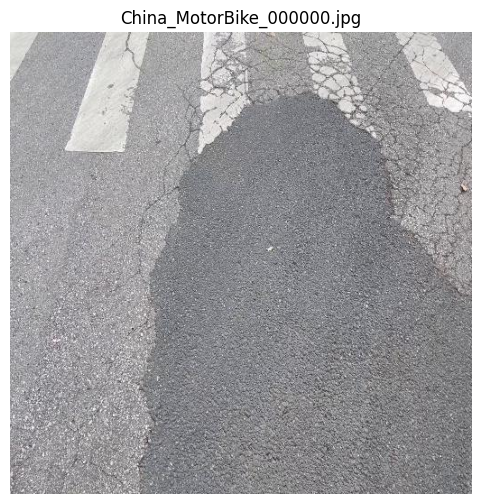

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

pays = RACINE_COLAB / "China_MotorBike"

if not pays.exists():
    raise FileNotFoundError("Le dossier China_MotorBike est introuvable.")

# Recherche des images dans les dossiers contenant 'train'
images_train = sorted([
    f for f in pays.rglob("*")
    if f.is_file()
    and "train" in f.relative_to(pays).parts
    and f.suffix.lower() in {".jpg", ".jpeg", ".png"}
])

if not images_train:
    raise FileNotFoundError("Aucune image d'entraînement trouvée.")

chemin_image = images_train[0]

with Image.open(chemin_image) as originale:
    print("Mode d'origine :", originale.mode)
    image = originale.convert("RGB")

pixels = np.asarray(image)

print("Fichier :", chemin_image.name)
print("Dimensions (largeur, hauteur) :", image.size)
print("Forme du tableau :", pixels.shape)
print("Type des valeurs :", pixels.dtype)
print("Pixel en haut à gauche [R, G, B] :", pixels[0, 0])

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.title(chemin_image.name)
plt.axis("off")
plt.show()

In [ ]:
# Recherche du XML correspondant
candidats = [
    f for f in pays.rglob("*.xml")
    if f.stem == chemin_image.stem
    and "train" in f.relative_to(pays).parts
]

if len(candidats) != 1:
    raise RuntimeError(f"Une annotation attendue, {len(candidats)} trouvée(s).")

chemin_xml = candidats[0]
annotation = ET.parse(chemin_xml).getroot()

print("XML :", chemin_xml.name)
print(
    "Dimensions déclarées :",
    annotation.findtext("size/width"),
    "×",
    annotation.findtext("size/height")
)

objets = annotation.findall("object")
print("Nombre d'objets annotés :", len(objets))

for numero, objet in enumerate(objets, start=1):
    classe = objet.findtext("name")
    coordonnees = [
        objet.findtext(f"bndbox/{nom}")
        for nom in ("xmin", "ymin", "xmax", "ymax")
    ]
    print(f"Objet {numero} : classe {classe} | [xmin, ymin, xmax, ymax] = {coordonnees}")

XML : China_MotorBike_000000.xml
Dimensions déclarées : 512 × 512
Nombre d'objets annotés : 4
Objet 1 : classe Repair | [xmin, ymin, xmax, ymax] = ['141', '64', '512', '512']
Objet 2 : classe D20 | [xmin, ymin, xmax, ymax] = ['169', '1', '512', '180']
Objet 3 : classe D20 | [xmin, ymin, xmax, ymax] = ['419', '180', '512', '295']
Objet 4 : classe D00 | [xmin, ymin, xmax, ymax] = ['124', '1', '148', '45']


## 6. Split stratifié par pays et par classe

Le split `test` officiel du dataset ne contient **aucune annotation** : il était
réservé aux organisateurs de la compétition CRDDC'2022. Il est donc inutilisable.
On reconstruit notre propre split à partir des seules images annotées.

Stratégie retenue :
- Chaque pays contribue à 80 % au train, 10 % au val, 10 % au test.
- À l'intérieur de chaque pays, les images sont stratifiées par **classe dominante**
  (la classe la plus représentée dans l'image), afin que chaque ensemble contienne
  les quatre classes D00, D10, D20, D40 dans des proportions proches.
- Les classes non officielles (`Repair`) sont ignorées.
- Les images sans aucune classe officielle sont écartées.

L'objectif : aucun ensemble ne doit être privé d'une classe ou d'un pays, malgré
le déséquilibre brut constaté (ratio max/min allant jusqu'à 50).

In [9]:
import random
import shutil
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from pathlib import Path
from tqdm.auto import tqdm

CLASSES_OFFICIELLES = {"D00", "D10", "D20", "D40"}

RACINE_SOURCE = RACINE_COLAB
RACINE_SPLIT  = Path("/content/datasets/RDD2022_split")

PROP_TRAIN = 0.80
PROP_VAL   = 0.10

random.seed(GRAINE)

# ------------------------------------------------------------------
# 1. Détection de la vraie racine (structure en double)
# ------------------------------------------------------------------
sous_dossiers = [d for d in RACINE_SOURCE.iterdir() if d.is_dir()]
if len(sous_dossiers) == 1 and (sous_dossiers[0] / sous_dossiers[0].name).exists():
    VRAIE_RACINE = sous_dossiers[0]
else:
    VRAIE_RACINE = RACINE_SOURCE

print(f"Racine des pays : {VRAIE_RACINE}")
print(f"Pays détectés   : {[d.name for d in sorted(VRAIE_RACINE.iterdir()) if d.is_dir()]}")


def classe_dominante(xml_path):
    try:
        root = ET.parse(xml_path).getroot()
    except ET.ParseError:
        return None
    compteur = Counter()
    for obj in root.findall("object"):
        nom = obj.findtext("name")
        if nom in CLASSES_OFFICIELLES:
            compteur[nom] += 1
    if not compteur:
        return None
    return compteur.most_common(1)[0][0]


paires_par_pays = defaultdict(list)

for pays in sorted(VRAIE_RACINE.iterdir()):
    if not pays.is_dir():
        continue

    for xml in pays.rglob("*.xml"):
        parties = xml.relative_to(pays).parts
        if "test" in parties:
            continue

        img = None
        for ext in (".jpg", ".jpeg", ".png"):
            candidat = xml.with_suffix(ext)
            alt = Path(str(candidat).replace("/annotations/xmls/", "/images/"))
            if candidat.exists():
                img = candidat
                break
            if alt.exists():
                img = alt
                break
        if img is None:
            continue

        classe = classe_dominante(xml)
        if classe is None:
            continue

        paires_par_pays[pays.name].append((img, xml, classe))

total = sum(len(v) for v in paires_par_pays.values())
print(f"\nPaires éligibles : {total}\n")
for pays, paires in sorted(paires_par_pays.items()):
    c = Counter(cl for _, _, cl in paires)
    print(f"{pays:20s} : {len(paires):5d}  "
          f"D00={c['D00']:5d}  D10={c['D10']:5d}  "
          f"D20={c['D20']:5d}  D40={c['D40']:5d}")


# ------------------------------------------------------------------
# 2. Split stratifié
# ------------------------------------------------------------------
split_par_pays = {}

for pays, paires in paires_par_pays.items():
    par_classe = defaultdict(list)
    for img, xml, classe in paires:
        par_classe[classe].append((img, xml, classe))

    train, val, test = [], [], []

    for classe, liste in par_classe.items():
        random.shuffle(liste)
        n = len(liste)
        n_train = int(n * PROP_TRAIN)
        n_val   = int(n * PROP_VAL)
        train += liste[:n_train]
        val   += liste[n_train:n_train + n_val]
        test  += liste[n_train + n_val:]

    split_par_pays[pays] = {"train": train, "val": val, "test": test}

print(f"\n{'Pays':20s} {'Train':>6s} {'Val':>6s} {'Test':>6s}")
print("-" * 42)
for pays, d in sorted(split_par_pays.items()):
    print(f"{pays:20s} {len(d['train']):6d} {len(d['val']):6d} {len(d['test']):6d}")

total_train = sum(len(d["train"]) for d in split_par_pays.values())
total_val   = sum(len(d["val"])   for d in split_par_pays.values())
total_test  = sum(len(d["test"])  for d in split_par_pays.values())
print("-" * 42)
print(f"{'TOTAL':20s} {total_train:6d} {total_val:6d} {total_test:6d}")


# ------------------------------------------------------------------
# 3. Copie vers la nouvelle arborescence
# ------------------------------------------------------------------
def copier(paires, destination):
    dossier_img = destination / "images"
    dossier_ann = destination / "annotations"
    dossier_img.mkdir(parents=True, exist_ok=True)
    dossier_ann.mkdir(parents=True, exist_ok=True)
    for img, xml, _ in paires:
        shutil.copy2(img, dossier_img / img.name)
        shutil.copy2(xml, dossier_ann / xml.name)


RACINE_SPLIT.mkdir(parents=True, exist_ok=True)

for pays, d in split_par_pays.items():
    for ensemble, paires in d.items():
        destination = RACINE_SPLIT / pays / ensemble
        if destination.exists():
            shutil.rmtree(destination)
        copier(paires, destination)
        print(f"{pays}/{ensemble} : {len(paires)} paires copiées.")

print(f"\nSplit terminé dans : {RACINE_SPLIT}")


# ------------------------------------------------------------------
# 4. Vérification anti-fuite
# ------------------------------------------------------------------
def stems(dossier):
    return {f.stem for f in dossier.rglob("*") if f.is_file()}

for pays in split_par_pays:
    s_train = stems(RACINE_SPLIT / pays / "train")
    s_val   = stems(RACINE_SPLIT / pays / "val")
    s_test  = stems(RACINE_SPLIT / pays / "test")
    assert not (s_train & s_val),  f"Fuite Train/Val sur {pays} !"
    assert not (s_train & s_test), f"Fuite Train/Test sur {pays} !"
    assert not (s_val   & s_test), f"Fuite Val/Test sur {pays} !"

print("Aucune fuite de données détectée sur les 7 pays.")

Racine des pays : /content/datasets/RDD2022
Pays détectés   : ['China_Drone', 'China_MotorBike', 'Czech', 'India', 'Japan', 'Norway', 'United_States']

Paires éligibles : 23767

China_Drone          :  1919  D00=  826  D10=  861  D20=  181  D40=   51
China_MotorBike      :  1934  D00= 1099  D10=  407  D20=  337  D40=   91
Czech                :  1072  D00=  684  D10=  204  D20=   90  D40=   94
India                :  3223  D00=  735  D10=   25  D20= 1207  D40= 1256
Japan                :  7900  D00= 2013  D10= 1313  D20= 3571  D40= 1003
Norway               :  2914  D00= 2334  D10=  385  D20=   67  D40=  128
United_States        :  4805  D00= 3191  D10= 1177  D20=  386  D40=   51

Pays                  Train    Val   Test
------------------------------------------
China_Drone            1532    191    196
China_MotorBike        1545    191    198
Czech                   857    106    109
India                  2577    320    326
Japan                  6318    789    793
Norway         

In [10]:
# ------------------------------------------------------------------
# 2. Split stratifié : à l'intérieur de chaque pays, par classe dominante
# ------------------------------------------------------------------
split_par_pays = {}   # pays -> {"train": [...], "val": [...], "test": [...]}

for pays, paires in paires_par_pays.items():

    # Regrouper par classe dominante
    par_classe = defaultdict(list)
    for img, xml, classe in paires:
        par_classe[classe].append((img, xml, classe))

    train, val, test = [], [], []

    # Stratifier à l'intérieur de chaque classe
    for classe, liste in par_classe.items():
        random.shuffle(liste)
        n = len(liste)
        n_train = int(n * PROP_TRAIN)
        n_val   = int(n * PROP_VAL)

        train += liste[:n_train]
        val   += liste[n_train:n_train + n_val]
        test  += liste[n_train + n_val:]

    split_par_pays[pays] = {"train": train, "val": val, "test": test}

# --- Rapport ---
print(f"{'Pays':20s} {'Train':>6s} {'Val':>6s} {'Test':>6s}")
print("-" * 42)
for pays, d in sorted(split_par_pays.items()):
    print(f"{pays:20s} {len(d['train']):6d} {len(d['val']):6d} {len(d['test']):6d}")

total_train = sum(len(d["train"]) for d in split_par_pays.values())
total_val   = sum(len(d["val"])   for d in split_par_pays.values())
total_test  = sum(len(d["test"])  for d in split_par_pays.values())

print("-" * 42)
print(f"{'TOTAL':20s} {total_train:6d} {total_val:6d} {total_test:6d}")

Pays                  Train    Val   Test
------------------------------------------
China_Drone            1532    191    196
China_MotorBike        1545    191    198
Czech                   857    106    109
India                  2577    320    326
Japan                  6318    789    793
Norway                 2330    289    295
United_States          3841    479    485
------------------------------------------
TOTAL                 19000   2365   2402


In [11]:
# ------------------------------------------------------------------
# 3. Copie vers /content/datasets/RDD2022_split/<pays>/<ensemble>/
# ------------------------------------------------------------------
def copier(paires, destination):
    dossier_img = destination / "images"
    dossier_ann = destination / "annotations"
    dossier_img.mkdir(parents=True, exist_ok=True)
    dossier_ann.mkdir(parents=True, exist_ok=True)

    for img, xml, _ in paires:
        shutil.copy2(img, dossier_img / img.name)
        shutil.copy2(xml, dossier_ann / xml.name)


RACINE_SPLIT.mkdir(parents=True, exist_ok=True)

for pays, d in split_par_pays.items():
    for ensemble, paires in d.items():
        destination = RACINE_SPLIT / pays / ensemble
        if destination.exists():
            shutil.rmtree(destination)
        copier(paires, destination)
        print(f"{pays}/{ensemble} : {len(paires)} paires copiées.")

print(f"\nSplit terminé dans : {RACINE_SPLIT}")

China_Drone/train : 1532 paires copiées.
China_Drone/val : 191 paires copiées.
China_Drone/test : 196 paires copiées.
China_MotorBike/train : 1545 paires copiées.
China_MotorBike/val : 191 paires copiées.
China_MotorBike/test : 198 paires copiées.
Czech/train : 857 paires copiées.
Czech/val : 106 paires copiées.
Czech/test : 109 paires copiées.
India/train : 2577 paires copiées.
India/val : 320 paires copiées.
India/test : 326 paires copiées.
Japan/train : 6318 paires copiées.
Japan/val : 789 paires copiées.
Japan/test : 793 paires copiées.
Norway/train : 2330 paires copiées.
Norway/val : 289 paires copiées.
Norway/test : 295 paires copiées.
United_States/train : 3841 paires copiées.
United_States/val : 479 paires copiées.
United_States/test : 485 paires copiées.

Split terminé dans : /content/datasets/RDD2022_split


In [12]:
# ------------------------------------------------------------------
# 4. Vérification anti-fuite par pays
# ------------------------------------------------------------------
def stems(dossier):
    return {f.stem for f in dossier.rglob("*") if f.is_file()}

for pays in split_par_pays:
    s_train = stems(RACINE_SPLIT / pays / "train")
    s_val   = stems(RACINE_SPLIT / pays / "val")
    s_test  = stems(RACINE_SPLIT / pays / "test")

    assert not (s_train & s_val),  f"Fuite Train/Val sur {pays} !"
    assert not (s_train & s_test), f"Fuite Train/Test sur {pays} !"
    assert not (s_val   & s_test), f"Fuite Val/Test sur {pays} !"

print("Aucune fuite de données détectée sur les 7 pays.")

Aucune fuite de données détectée sur les 7 pays.


In [13]:
# ------------------------------------------------------------------
# 5. Vérification : distribution des classes dans chaque ensemble
# ------------------------------------------------------------------
stats_final = []

for pays in sorted(split_par_pays):
    for ensemble in ("train", "val", "test"):
        d = RACINE_SPLIT / pays / ensemble
        xmls = list((d / "annotations").glob("*.xml"))
        images = list((d / "images").glob("*"))

        compteur = Counter()
        for xml in xmls:
            try:
                root = ET.parse(xml).getroot()
            except ET.ParseError:
                continue
            for obj in root.findall("object"):
                nom = obj.findtext("name")
                if nom in CLASSES_OFFICIELLES:
                    compteur[nom] += 1

        stats_final.append({
            "Pays": pays, "Ensemble": ensemble,
            "Images": len(images),
            "D00": compteur["D00"], "D10": compteur["D10"],
            "D20": compteur["D20"], "D40": compteur["D40"],
        })

df_final = pd.DataFrame(stats_final)
print(df_final.to_string(index=False))

           Pays Ensemble  Images  D00  D10  D20  D40
    China_Drone    train    1532 1134 1001  237   68
    China_Drone      val     191  149  119   29    9
    China_Drone     test     196  143  143   27    9
China_MotorBike    train    1545 2092  868  514  181
China_MotorBike      val     191  302  113   59   22
China_MotorBike     test     198  284  115   68   32
          Czech    train     857  798  325  125  153
          Czech      val     106   93   33   20   26
          Czech     test     109   97   41   16   18
          India    train    2577 1237   56 1624 2539
          India      val     320  169    6  194  333
          India     test     326  149    6  203  315
          Japan    train    6318 3245 3226 4960 1813
          Japan      val     789  412  350  626  230
          Japan     test     793  392  403  613  200
         Norway    train    2330 6834 1419  373  365
         Norway      val     289  871  155   32   40
         Norway     test     295  865  156   6

## 7. EDA — Distribution par pays

Première exploration : combien d'images et d'annotations par pays, et combien
d'instances par classe (D00, D10, D20, D40). C'est la base pour construire un
split stratifié correct.

In [ ]:
import xml.etree.ElementTree as ET
from collections import Counter
import pandas as pd

racine = RACINE_COLAB

# Classes officielles RDD2022
CLASSES = {
    "D00": "Fissure longitudinale",
    "D10": "Fissure transversale",
    "D20": "Fissure alligator",
    "D40": "Nid-de-poule",
}

stats = []

for pays in sorted(racine.iterdir()):
    if not pays.is_dir():
        continue

    images = [f for f in pays.rglob("*")
              if f.is_file() and f.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    xmls = [f for f in pays.rglob("*.xml") if f.is_file()]

    # Comptage des instances par classe
    compteur = Counter()
    for xml in xmls:
        try:
            root = ET.parse(xml).getroot()
        except ET.ParseError:
            continue
        for obj in root.findall("object"):
            classe = obj.findtext("name")
            if classe:
                compteur[classe] += 1

    ligne = {
        "Pays": pays.name,
        "Images": len(images),
        "XML": len(xmls),
    }
    for c in CLASSES:
        ligne[c] = compteur.get(c, 0)
    ligne["Total_instances"] = sum(compteur.values())

    stats.append(ligne)

df_stats = pd.DataFrame(stats)
print(df_stats.to_string(index=False))

           Pays  Images   XML  D00  D10  D20  D40  Total_instances
    China_Drone    2401  2401 1426 1263  293   86             3840
China_MotorBike    2477  1977 2678 1096  641  235             4927
          Czech    3538  2829  988  399  161  197             1745
          India    9665  7706 1555   68 2021 3187             8203
          Japan   13133 10506 4049 3979 6199 2243            24754
         Norway   10201  8161 8570 1730  468  461            11229
  United_States    6005  4805 6750 3295  834  135            11014


## 8. Distribution par split interne

Le dataset est livré avec des dossiers `train` et `test` à l'intérieur de chaque
pays. On vérifie leur contenu respectif avant de fusionner pour reconstruire
notre propre split.

In [ ]:
stats_split = []

for pays in sorted(racine.iterdir()):
    if not pays.is_dir():
        continue

    for nom_split in ("train", "test"):
        for dossier in pays.rglob(nom_split):
            if not dossier.is_dir():
                continue

            images = [f for f in dossier.rglob("*")
                      if f.is_file() and f.suffix.lower() in {".jpg", ".jpeg", ".png"}]
            xmls = [f for f in dossier.rglob("*.xml") if f.is_file()]

            compteur = Counter()
            for xml in xmls:
                try:
                    root = ET.parse(xml).getroot()
                except ET.ParseError:
                    continue
                for obj in root.findall("object"):
                    classe = obj.findtext("name")
                    if classe:
                        compteur[classe] += 1

            stats_split.append({
                "Pays": pays.name,
                "Split": nom_split,
                "Images": len(images),
                "XML": len(xmls),
                **{c: compteur.get(c, 0) for c in CLASSES},
            })

df_split = pd.DataFrame(stats_split)
print(df_split.to_string(index=False))

           Pays Split  Images   XML  D00  D10  D20  D40
    China_Drone train    2401  2401 1426 1263  293   86
China_MotorBike train    1977  1977 2678 1096  641  235
China_MotorBike  test     500     0    0    0    0    0
          Czech train    2829  2829  988  399  161  197
          Czech  test     709     0    0    0    0    0
          India train    7706  7706 1555   68 2021 3187
          India  test    1959     0    0    0    0    0
          Japan train   10506 10506 4049 3979 6199 2243
          Japan  test    2627     0    0    0    0    0
         Norway train    8161  8161 8570 1730  468  461
         Norway  test    2040     0    0    0    0    0
  United_States train    4805  4805 6750 3295  834  135
  United_States  test    1200     0    0    0    0    0


## 9. Déséquilibre des classes

Visualisation du rapport entre la classe majoritaire et la classe minoritaire
par pays. Un ratio élevé signifie qu'il faudra pondérer la loss ou sur-échantillonner.

           Pays  Total_instances  Ratio_max_min
    China_Drone             3840           16.6
China_MotorBike             4927           11.4
          Czech             1745            6.1
          India             8203           46.9
          Japan            24754            2.8
         Norway            11229           18.6
  United_States            11014           50.0


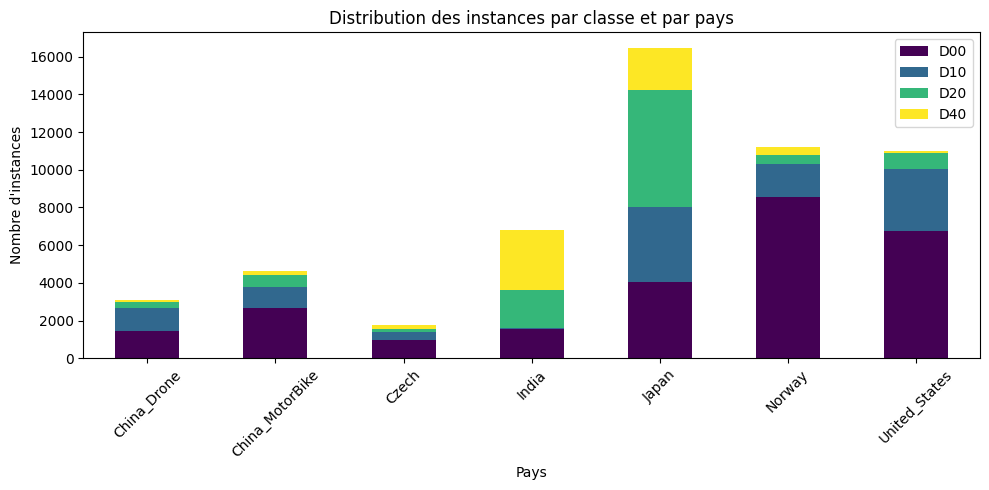

In [ ]:
df_stats["Ratio_max_min"] = df_stats[[c for c in CLASSES]].apply(
    lambda row: row.max() / max(row.min(), 1), axis=1
).round(1)

print(df_stats[["Pays", "Total_instances", "Ratio_max_min"]].to_string(index=False))

# Visualisation en barres empilées
df_plot = df_stats.set_index("Pays")[list(CLASSES.keys())]
df_plot.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="viridis")
plt.title("Distribution des instances par classe et par pays")
plt.ylabel("Nombre d'instances")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

racine = RACINE_COLAB

# Arborescence réelle d'un pays, sur 3 niveaux
pays = racine / "China_Drone"
print(f"Racine pays : {pays}")
print(f"Existe      : {pays.exists()}\n")

for p in sorted(pays.rglob("*"))[:20]:
    niveau = len(p.relative_to(pays).parts)
    type_ = "DIR " if p.is_dir() else "FILE"
    print(f"{'  ' * niveau}{type_} {p.relative_to(pays)}")

# Combien de XML au total et où
xmls = list(pays.rglob("*.xml"))
print(f"\nXML trouvés : {len(xmls)}")
if xmls:
    print(f"Premier XML : {xmls[0]}")
    print(f"Parts du chemin relatif : {xmls[0].relative_to(pays).parts}")

Racine pays : /content/datasets/RDD2022/China_Drone
Existe      : True

  DIR  China_Drone
    DIR  China_Drone/train
      DIR  China_Drone/train/annotations
        DIR  China_Drone/train/annotations/xmls
          FILE China_Drone/train/annotations/xmls/China_Drone_000000.xml
          FILE China_Drone/train/annotations/xmls/China_Drone_000001.xml
          FILE China_Drone/train/annotations/xmls/China_Drone_000002.xml
          FILE China_Drone/train/annotations/xmls/China_Drone_000003.xml
          FILE China_Drone/train/annotations/xmls/China_Drone_000004.xml
          FILE China_Drone/train/annotations/xmls/China_Drone_000005.xml
          FILE China_Drone/train/annotations/xmls/China_Drone_000006.xml
          FILE China_Drone/train/annotations/xmls/China_Drone_000007.xml
          FILE China_Drone/train/annotations/xmls/China_Drone_000008.xml
          FILE China_Drone/train/annotations/xmls/China_Drone_000009.xml
          FILE China_Drone/train/annotations/xmls/China_Drone_0

## 10. Prétraitement — CLAHE

Le contraste local des fissures est faible sur fond de chaussée texturée. On applique
CLAHE (Contrast Limited Adaptive Histogram Equalization) sur le canal L de l'espace
LAB, afin de rehausser les traits fins sans amplifier le bruit global.
La fonction est définie ici, elle sera appelée à la volée par le DataLoader.

In [14]:
import cv2
import numpy as np

def appliquer_clahe(image_rgb, clip_limit=2.0, tile_grid=(8, 8)):
    """
    Applique CLAHE sur le canal L de l'espace LAB.
    Entrée  : image RGB (uint8, HxWx3)
    Sortie  : image RGB rehaussée (uint8, HxWx3)
    """
    # Conversion RGB -> LAB
    lab = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    # CLAHE sur le canal L uniquement
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    l_egalise = clahe.apply(l)

    # Reconstruction LAB -> RGB
    lab_egalise = cv2.merge((l_egalise, a, b))
    return cv2.cvtColor(lab_egalise, cv2.COLOR_LAB2RGB)

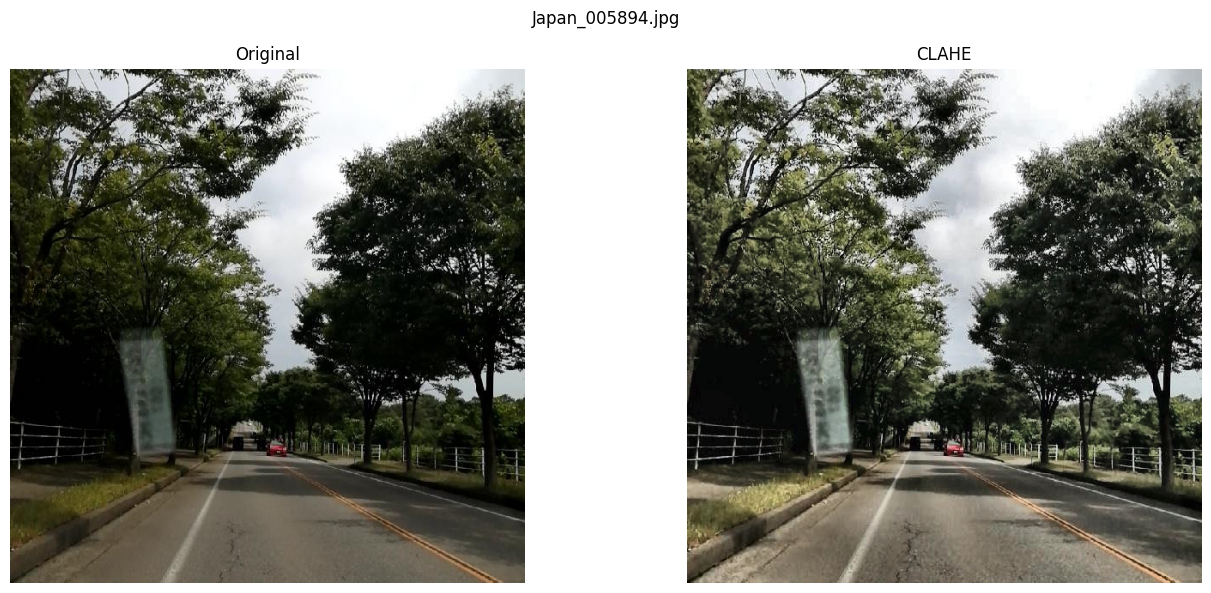

In [15]:
# --- Démonstration visuelle sur une image du split ---
from PIL import Image
import matplotlib.pyplot as plt

exemple = next((RACINE_SPLIT / "Japan" / "train" / "images").glob("*.jpg"))
img_orig = np.array(Image.open(exemple).convert("RGB"))
img_clahe = appliquer_clahe(img_orig)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(img_orig);  axes[0].set_title("Original");  axes[0].axis("off")
axes[1].imshow(img_clahe); axes[1].set_title("CLAHE");     axes[1].axis("off")
plt.suptitle(exemple.name)
plt.tight_layout()
plt.show()

## 11. Conversion des annotations

Les XML Pascal VOC doivent être convertis en tenseurs. On produit deux formats :
- **Format YOLO** : `[classe, x_centre, y_centre, largeur, hauteur]`, valeurs normalisées.
- **Format générique** : `[xmin, ymin, xmax, ymax, classe]`, valeurs absolues, réutilisable
  pour Faster R-CNN ou pour l'évaluation.

Une image peut contenir plusieurs objets. Les classes non officielles (`Repair`) sont
ignorées. La correspondance classe → indice est fixée une fois pour toutes.

In [16]:
import xml.etree.ElementTree as ET

# --- Mapping classe -> indice (fixe, à réutiliser à l'entraînement et à l'évaluation) ---
CLASSES = ["D00", "D10", "D20", "D40"]
CLASSE_VERS_IDX = {c: i for i, c in enumerate(CLASSES)}
IDX_VERS_CLASSE = {i: c for c, i in CLASSE_VERS_IDX.items()}


def lire_annotations_voc(xml_path, classes_autorisees=CLASSES):
    """
    Lit un XML Pascal VOC et retourne :
      - une liste de tuples (classe_idx, xmin, ymin, xmax, ymax) en coordonnées absolues.
    Les classes non autorisées (ex: 'Repair') sont ignorées.
    """
    root = ET.parse(xml_path).getroot()
    boites = []
    for obj in root.findall("object"):
        nom = obj.findtext("name")
        if nom not in classes_autorisees:
            continue
        bnd = obj.find("bndbox")
        xmin = float(bnd.findtext("xmin"))
        ymin = float(bnd.findtext("ymin"))
        xmax = float(bnd.findtext("xmax"))
        ymax = float(bnd.findtext("ymax"))
        boites.append((CLASSE_VERS_IDX[nom], xmin, ymin, xmax, ymax))
    return boites


def voc_vers_yolo(boites, largeur, hauteur):
    """Convertit une liste VOC absolue en lignes YOLO normalisées."""
    lignes = []
    for classe_idx, xmin, ymin, xmax, ymax in boites:
        xc = ((xmin + xmax) / 2) / largeur
        yc = ((ymin + ymax) / 2) / hauteur
        w  = (xmax - xmin) / largeur
        h  = (ymax - ymin) / hauteur
        lignes.append(f"{classe_idx} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")
    return lignes


# --- Test sur un exemple ---
exemple_xml = next((RACINE_SPLIT / "Japan" / "train" / "annotations").glob("*.xml"))
root = ET.parse(exemple_xml).getroot()
largeur = int(root.findtext("size/width"))
hauteur = int(root.findtext("size/height"))

boites = lire_annotations_voc(exemple_xml)
print(f"XML    : {exemple_xml.name}")
print(f"Taille : {largeur} x {hauteur}")
print(f"Objets : {boites}")

for ligne in voc_vers_yolo(boites, largeur, hauteur):
    print("  YOLO :", ligne)

XML    : Japan_003398.xml
Taille : 600 x 600
Objets : [(3, 437.0, 545.0, 489.0, 585.0), (2, 328.0, 348.0, 416.0, 416.0), (2, 347.0, 455.0, 565.0, 578.0)]
  YOLO : 3 0.771667 0.941667 0.086667 0.066667
  YOLO : 2 0.620000 0.636667 0.146667 0.113333
  YOLO : 2 0.760000 0.860833 0.363333 0.205000


## 12. Dataset PyTorch

On encapsule le chargement dans une classe `Dataset` PyTorch. Chaque `__getitem__`
retourne :
  - l'image redimensionnée et prétraitée (CLAHE + normalisation),
  - les cibles au format tenseur (utile pour l'entraînement),
  - les dimensions originales (pour reprojeter les prédictions à l'échelle native).

Aucun prétraitement n'est écrit sur disque : tout est fait à la volée, ce qui évite
de dupliquer 40 Go de données.

In [17]:
import torch
from torch.utils.data import Dataset
from PIL import Image


class RDDDataset(Dataset):
    """
    Dataset RDD2022 pour la détection d'objets.
    Charge une image, applique CLAHE, redimensionne, normalise,
    et retourne les cibles au format [classe, xc, yc, w, h] normalisées.
    """

    def __init__(self, racine, pays, ensemble, taille=640, use_clahe=True):
        self.dossier_img = RACINE_SPLIT / pays / ensemble / "images"
        self.dossier_ann = RACINE_SPLIT / pays / ensemble / "annotations"
        self.taille = taille
        self.use_clahe = use_clahe

        # Liste des images ayant un XML correspondant
        self.images = sorted([
            f for f in self.dossier_img.iterdir()
            if f.suffix.lower() in {".jpg", ".jpeg", ".png"}
            and (self.dossier_ann / (f.stem + ".xml")).exists()
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        chemin_img = self.images[idx]
        chemin_xml = self.dossier_ann / (chemin_img.stem + ".xml")

        # --- Chargement image ---
        img = np.array(Image.open(chemin_img).convert("RGB"))
        h_orig, w_orig = img.shape[:2]

        # --- CLAHE ---
        if self.use_clahe:
            img = appliquer_clahe(img)

        # --- Redimensionnement ---
        img_resized = cv2.resize(img, (self.taille, self.taille),
                                 interpolation=cv2.INTER_LINEAR)

        # --- Normalisation [0,1] puis tenseur CHW ---
        img_tensor = torch.from_numpy(img_resized).float().permute(2, 0, 1) / 255.0

        # --- Cibles ---
        boites = lire_annotations_voc(chemin_xml)
        lignes = voc_vers_yolo(boites, w_orig, h_orig)

        cibles = []
        for ligne in lignes:
            parts = ligne.split()
            cibles.append([float(p) for p in parts])
        cibles = torch.tensor(cibles, dtype=torch.float32) if cibles else torch.zeros((0, 5))

        return {
            "image": img_tensor,
            "cibles": cibles,
            "chemin": str(chemin_img),
            "taille_originale": (h_orig, w_orig),
        }


# --- Test sur le split Japan/train ---
ds_test = RDDDataset(RACINE_SPLIT, "Japan", "train")
print(f"Taille du dataset : {len(ds_test)} images")

echantillon = ds_test[0]
print(f"Image      : {echantillon['chemin']}")
print(f"Tenseur    : {echantillon['image'].shape} | {echantillon['image'].dtype}")
print(f"Cibles     : {echantillon['cibles'].shape}")
print(f"Taille orig: {echantillon['taille_originale']}")
print(f"Première cible : {echantillon['cibles'][0] if len(echantillon['cibles']) else 'aucune'}")

Taille du dataset : 6318 images
Image      : /content/datasets/RDD2022_split/Japan/train/images/Japan_000001.jpg
Tenseur    : torch.Size([3, 640, 640]) | torch.float32
Cibles     : torch.Size([2, 5])
Taille orig: (600, 600)
Première cible : tensor([1.0000, 0.6142, 0.7300, 0.7650, 0.0767])


## 13. DataLoaders et déséquilibre des classes

Le déséquilibre intra-ensemble est important (jusqu'à 1:50 selon les pays). Deux
leviers sont utilisés conjointement :

1. **WeightedRandomSampler** : chaque image est tirée avec une probabilité
   inversement proportionnelle à la fréquence de sa classe dominante. Les classes
   rares sont vues plus souvent.
2. **Pondération de la loss** (définie plus tard, au moment de l'entraînement) :
   les erreurs sur les classes rares pèsent davantage.

Ici on met en place les DataLoaders avec le sampler pondéré. Le batch size est
modeste (8) pour tenir sur T4 avec des images 640x640.

In [18]:
from torch.utils.data import DataLoader, WeightedRandomSampler
from collections import Counter

def construire_sampler(dataset):
    """WeightedRandomSampler basé sur la classe dominante de chaque image."""
    classes_dominantes = []
    for chemin in dataset.images:
        xml = dataset.dossier_ann / (chemin.stem + ".xml")
        boites = lire_annotations_voc(xml)
        if not boites:
            classes_dominantes.append(None)
            continue
        c = Counter(b[0] for b in boites)
        classes_dominantes.append(c.most_common(1)[0][0])

    freq = Counter(cl for cl in classes_dominantes if cl is not None)
    total = sum(freq.values())
    poids_par_classe = {cl: total / freq[cl] for cl in freq}

    poids_images = [
        poids_par_classe[cl] if cl is not None else 1.0
        for cl in classes_dominantes
    ]

    return WeightedRandomSampler(
        weights=torch.tensor(poids_images, dtype=torch.float32),
        num_samples=len(poids_images),
        replacement=True,
    )


def collate_detection(batch):
    """
    Collate personnalisé pour la détection d'objets.
    Empile les images (taille fixe) mais conserve les cibles
    sous forme de liste, car chaque image a un nombre d'objets différent.
    """
    images = torch.stack([item["image"] for item in batch], dim=0)
    cibles = [item["cibles"] for item in batch]
    chemins = [item["chemin"] for item in batch]
    tailles = [item["taille_originale"] for item in batch]
    return {
        "image": images,
        "cibles": cibles,        # liste de tenseurs, pas empilés
        "chemin": chemins,
        "taille_originale": tailles,
    }


# --- Construction des datasets ---
ds_train = RDDDataset(RACINE_SPLIT, "Japan", "train", taille=640, use_clahe=True)
ds_val   = RDDDataset(RACINE_SPLIT, "Japan", "val",   taille=640, use_clahe=True)
ds_test  = RDDDataset(RACINE_SPLIT, "Japan", "test",  taille=640, use_clahe=True)

print(f"Train : {len(ds_train)} | Val : {len(ds_val)} | Test : {len(ds_test)}")

# --- Sampler pondéré (train uniquement) ---
sampler_train = construire_sampler(ds_train)

# --- DataLoaders avec collate_fn ---
dl_train = DataLoader(
    ds_train, batch_size=8, sampler=sampler_train,
    num_workers=2, collate_fn=collate_detection,
)
dl_val = DataLoader(
    ds_val, batch_size=8, shuffle=False,
    num_workers=2, collate_fn=collate_detection,
)
dl_test = DataLoader(
    ds_test, batch_size=8, shuffle=False,
    num_workers=2, collate_fn=collate_detection,
)

# --- Vérification ---
batch = next(iter(dl_train))
print(f"\nBatch image  : {batch['image'].shape}")
print(f"Batch cibles : {len(batch['cibles'])} tenseurs")
print(f"Tailles      : {[t.shape[0] for t in batch['cibles']]}")
print(f"Exemple      : {batch['cibles'][0]}")

Train : 6318 | Val : 789 | Test : 793

Batch image  : torch.Size([8, 3, 640, 640])
Batch cibles : 8 tenseurs
Tailles      : [1, 1, 2, 2, 5, 6, 1, 5]
Exemple      : tensor([[3.0000, 0.0683, 0.7450, 0.1333, 0.0500]])


## 14. Visualisation des annotations

Contrôle visuel : on superpose les bounding boxes aux images pour vérifier que
la conversion VOC → tenseur n'a pas introduit d'erreur de coordonnées.
Une couleur par classe, pour repérer visuellement la distribution locale.

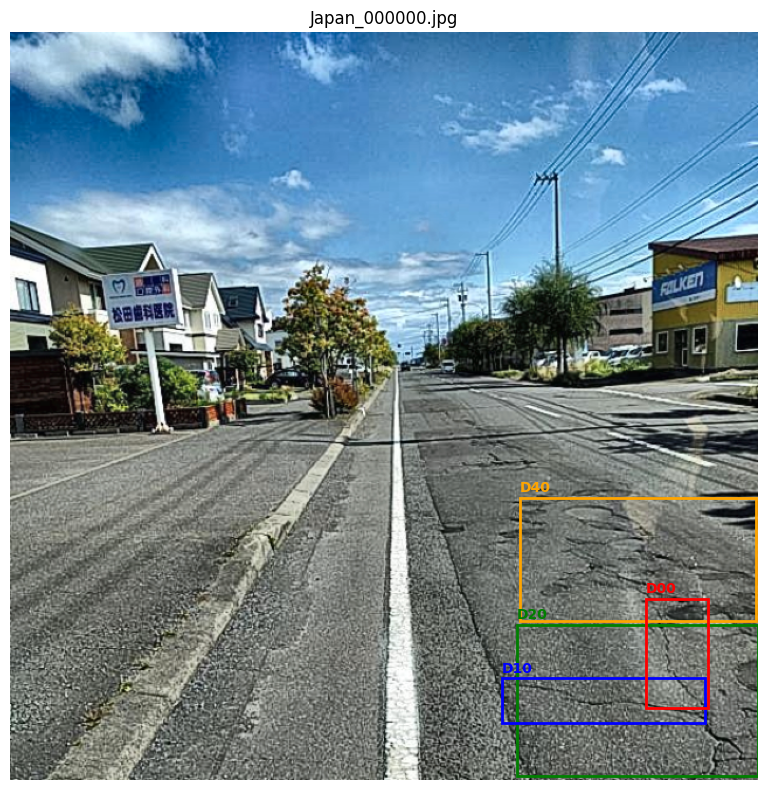

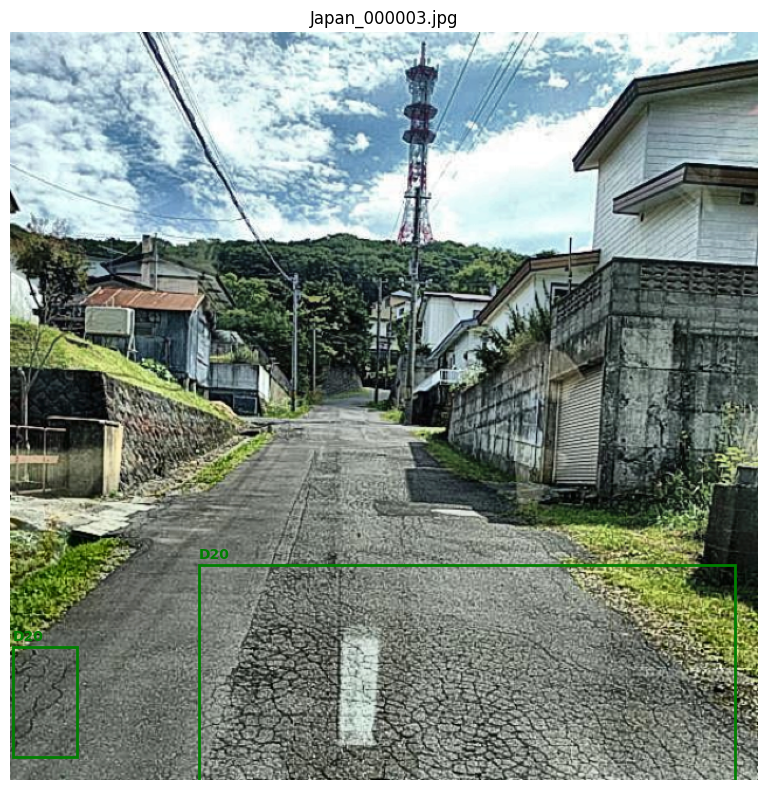

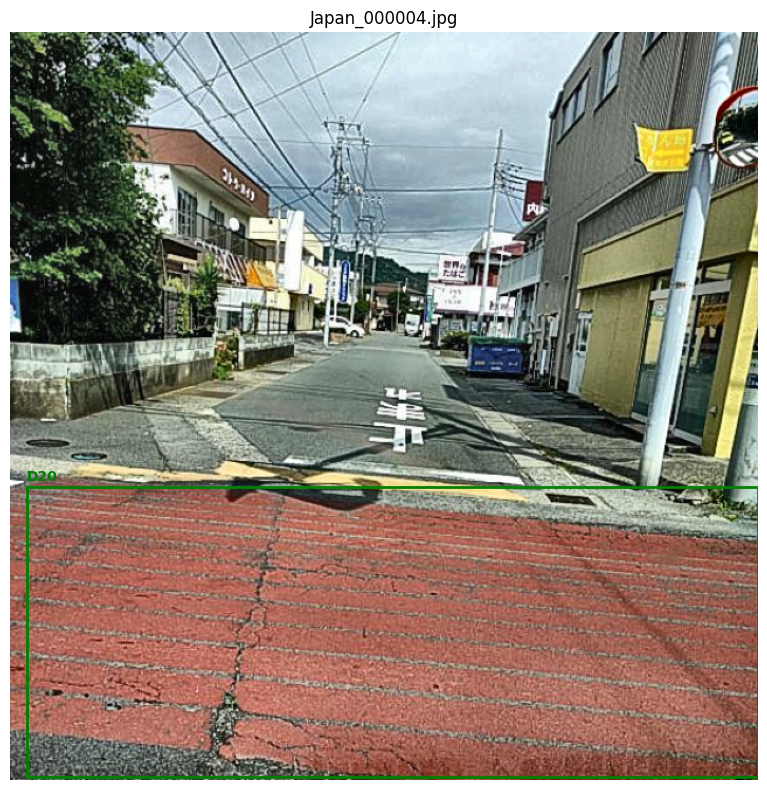

In [ ]:
import matplotlib.patches as patches

COULEURS = {"D00": "red", "D10": "blue", "D20": "green", "D40": "orange"}

def visualiser_echantillon(dataset, idx):
    item = dataset[idx]
    img = item["image"].permute(1, 2, 0).numpy()
    cibles = item["cibles"]
    h, w = 640, 640

    fig, ax = plt.subplots(1, 1, figsize=(8, 8))
    ax.imshow(img)

    for cible in cibles:
        classe_idx, xc, yc, bw, bh = cible.tolist()
        nom = IDX_VERS_CLASSE[int(classe_idx)]

        # Convertir centre/largeur/hauteur -> coin supérieur gauche
        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        rect = patches.Rectangle(
            (x1, y1), bw * w, bh * h,
            linewidth=2, edgecolor=COULEURS[nom], facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(x1, y1 - 5, nom, color=COULEURS[nom], fontsize=10, weight="bold")

    ax.set_title(Path(item["chemin"]).name)
    ax.axis("off")
    plt.tight_layout()
    plt.show()


# --- Afficher 3 échantillons du train ---
for i in range(3):
    visualiser_echantillon(ds_train, i)

## 15. Installation de YOLOv8

On installe Ultralytics, la bibliothèque officielle de YOLOv8. On vérifie ensuite
que la version CUDA est bien détectée, pour garantir que l'entraînement se fera
sur GPU et non sur CPU.

In [19]:
!pip install -q ultralytics

import ultralytics
from ultralytics import YOLO

ultralytics.checks()

print(f"Ultralytics : {ultralytics.__version__}")
print(f"CUDA dispo  : {torch.cuda.is_available()}")
print(f"GPU         : {torch.cuda.get_device_name(0)}")

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 50.9/107.7 GB disk)
Ultralytics : 8.4.175
CUDA dispo  : False


AssertionError: Torch not compiled with CUDA enabled

## 16. Conversion des annotations vers le format YOLO

YOLOv8 ne lit pas les XML Pascal VOC nativement. Il attend :
- un fichier `.txt` par image, nommé comme l'image,
- une ligne par objet au format `classe xc yc w h` (valeurs normalisées),
- un fichier `data.yaml` décrivant les chemins et les classes.

On convertit donc l'ensemble du split (7 pays × 3 ensembles) en écrivant les
fichiers `.txt` à côté des images. Ceci est fait une seule fois et sera versionné
avec DVC dans la phase MLOps.

In [ ]:
import yaml
from pathlib import Path
import xml.etree.ElementTree as ET

# --- Configuration ---
CLASSES = ["D00", "D10", "D20", "D40"]
CLASSE_VERS_IDX = {c: i for i, c in enumerate(CLASSES)}

RACINE_SPLIT = Path("/content/datasets/RDD2022_split")
RACINE_YOLO  = Path("/content/datasets/RDD2022_yolo")


def convertir_split_en_yolo(pays, ensemble):
    """
    Convertit un couple (pays, ensemble) au format attendu par YOLOv8 :
      RACINE_YOLO/pays/ensemble/images/*.jpg
      RACINE_YOLO/pays/ensemble/labels/*.txt
    """
    src_img = RACINE_SPLIT / pays / ensemble / "images"
    src_ann = RACINE_SPLIT / pays / ensemble / "annotations"

    dst_img = RACINE_YOLO / pays / ensemble / "images"
    dst_lab = RACINE_YOLO / pays / ensemble / "labels"
    dst_img.mkdir(parents=True, exist_ok=True)
    dst_lab.mkdir(parents=True, exist_ok=True)

    n_converties = 0

    for chemin_img in sorted(src_img.iterdir()):
        if chemin_img.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue

        chemin_xml = src_ann / (chemin_img.stem + ".xml")
        if not chemin_xml.exists():
            continue

        # Lecture XML
        root = ET.parse(chemin_xml).getroot()
        largeur  = int(root.findtext("size/width"))
        hauteur  = int(root.findtext("size/height"))

        lignes = []
        for obj in root.findall("object"):
            nom = obj.findtext("name")
            if nom not in CLASSE_VERS_IDX:
                continue

            bnd = obj.find("bndbox")
            xmin = float(bnd.findtext("xmin"))
            ymin = float(bnd.findtext("ymin"))
            xmax = float(bnd.findtext("xmax"))
            ymax = float(bnd.findtext("ymax"))

            xc = ((xmin + xmax) / 2) / largeur
            yc = ((ymin + ymax) / 2) / hauteur
            w  = (xmax - xmin) / largeur
            h  = (ymax - ymin) / hauteur

            lignes.append(f"{CLASSE_VERS_IDX[nom]} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")

        # Écriture des fichiers .txt (un même si vide, YOLO l'accepte)
        chemin_txt = dst_lab / (chemin_img.stem + ".txt")
        chemin_txt.write_text("\n".join(lignes), encoding="utf-8")

        # Lien symbolique pour l'image (évite de dupliquer 40 Go)
        chemin_dst_img = dst_img / chemin_img.name
        if not chemin_dst_img.exists():
            chemin_dst_img.symlink_to(chemin_img)

        n_converties += 1

    return n_converties


# --- Conversion pour les 7 pays × 3 ensembles ---
total = 0
for pays in sorted([d.name for d in RACINE_SPLIT.iterdir() if d.is_dir()]):
    for ensemble in ("train", "val", "test"):
        n = convertir_split_en_yolo(pays, ensemble)
        total += n
        print(f"{pays:20s} {ensemble:5s} : {n:5d} images converties")

print(f"\nTotal converti : {total} images")

China_Drone          train :  1532 images converties
China_Drone          val   :   191 images converties
China_Drone          test  :   196 images converties
China_MotorBike      train :  1545 images converties
China_MotorBike      val   :   191 images converties
China_MotorBike      test  :   198 images converties
Czech                train :   857 images converties
Czech                val   :   106 images converties
Czech                test  :   109 images converties
India                train :  2577 images converties
India                val   :   320 images converties
India                test  :   326 images converties
Japan                train :  6318 images converties
Japan                val   :   789 images converties
Japan                test  :   793 images converties
Norway               train :  2330 images converties
Norway               val   :   289 images converties
Norway               test  :   295 images converties
United_States        train :  3841 images conv

In [ ]:
# --- Fichier data.yaml décrivant le dataset pour YOLOv8 ---
data_yaml = {
    "path":  str(RACINE_YOLO),
    "train": ["China_Drone/train", "China_MotorBike/train", "Czech/train",
              "India/train", "Japan/train", "Norway/train", "United_States/train"],
    "val":   ["China_Drone/val", "China_MotorBike/val", "Czech/val",
              "India/val", "Japan/val", "Norway/val", "United_States/val"],
    "test":  ["China_Drone/test", "China_MotorBike/test", "Czech/test",
              "India/test", "Japan/test", "Norway/test", "United_States/test"],
    "nc": 4,
    "names": {i: c for i, c in enumerate(CLASSES)},
}

chemin_yaml = RACINE_YOLO / "data.yaml"
chemin_yaml.write_text(yaml.safe_dump(data_yaml, sort_keys=False, allow_unicode=True),
                       encoding="utf-8")

print(chemin_yaml.read_text())

path: /content/datasets/RDD2022_yolo
train:
- China_Drone/train
- China_MotorBike/train
- Czech/train
- India/train
- Japan/train
- Norway/train
- United_States/train
val:
- China_Drone/val
- China_MotorBike/val
- Czech/val
- India/val
- Japan/val
- Norway/val
- United_States/val
test:
- China_Drone/test
- China_MotorBike/test
- Czech/test
- India/test
- Japan/test
- Norway/test
- United_States/test
nc: 4
names:
  0: D00
  1: D10
  2: D20
  3: D40



## 17. Fine-tuning de YOLOv8

On part des poids `yolov8s.pt` (pré-entraînés sur COCO). La tête de détection est
automatiquement réadaptée à 4 classes. Le déséquilibre est géré en interne par
YOLOv8 (loss pondérée) — on complète avec les hyperparamètres d'augmentation.

Stratégie : entraînement court (20 époques) en premier lieu pour valider le
pipeline complet, avant d'allonger.

In [ ]:
from ultralytics import YOLO

# --- Chargement du modèle pré-entraîné ---
modele = YOLO("yolov8s.pt")   # 's' = small, bon compromis vitesse/précision

# --- Entraînement ---
resultats = modele.train(
    data=str(chemin_yaml),
    epochs=20,
    imgsz=640,
    batch=16,
    device=0,                # GPU 0
    workers=2,
    project="/content/drive/MyDrive/Datasets/RDD2022_runs",
    name="yolov8s_baseline",
    exist_ok=True,
    pretrained=True,
    optimizer="AdamW",
    lr0=0.001,
    patience=5,
    verbose=True,
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/RDD2022_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_baseline, nbs=64, nms=None, opset=None, 

In [ ]:
# --- Évaluation sur le jeu de test ---
metriques = modele.val(
    data=str(chemin_yaml),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
)

print(f"mAP@50    : {metriques.box.map50:.4f}")
print(f"mAP@50-95 : {metriques.box.map:.4f}")
print(f"Précision : {metriques.box.mp:.4f}")
print(f"Rappel    : {metriques.box.mr:.4f}")

# --- Détail par classe ---
for i, nom in enumerate(CLASSES):
    print(f"  {nom} : AP@50 = {metriques.box.ap50[i]:.4f}")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 40.8±6.9 MB/s, size: 62.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/datasets/RDD2022_yolo/China_Drone/test/labels... 2402 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2402/2402 563.5it/s 4.3s
val: New cache created: /content/datasets/RDD2022_yolo/China_Drone/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 151/151 3.2it/s 47.3s
                   all       2402       5549       0.63      0.534      0.573      0.289
                   D00       1364       2576      0.617      0.538      0.573      0.312
                   D10        769       1182       0

## 18. Courbes d'entraînement

YOLOv8 sauvegarde automatiquement les courbes dans le dossier `runs/`. On les
affiche pour diagnostiquer la convergence : pertes, mAP, précision, rappel.

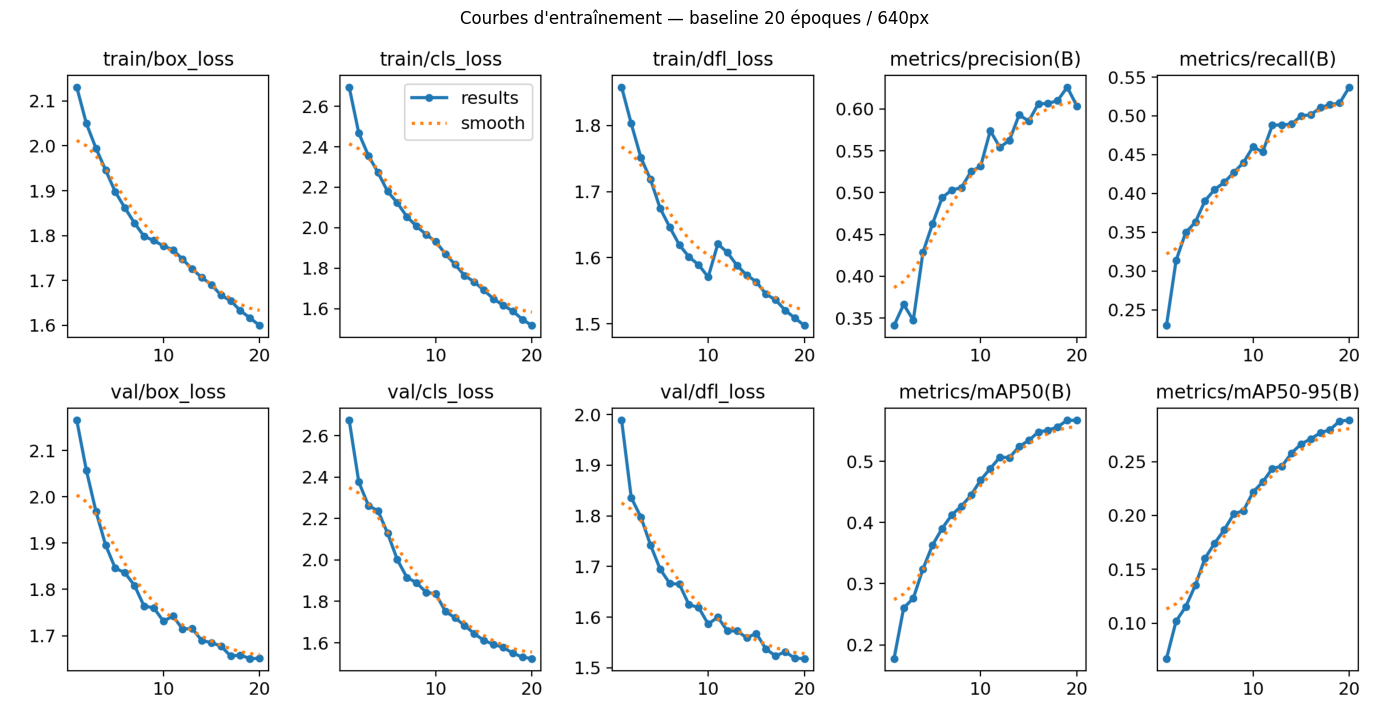

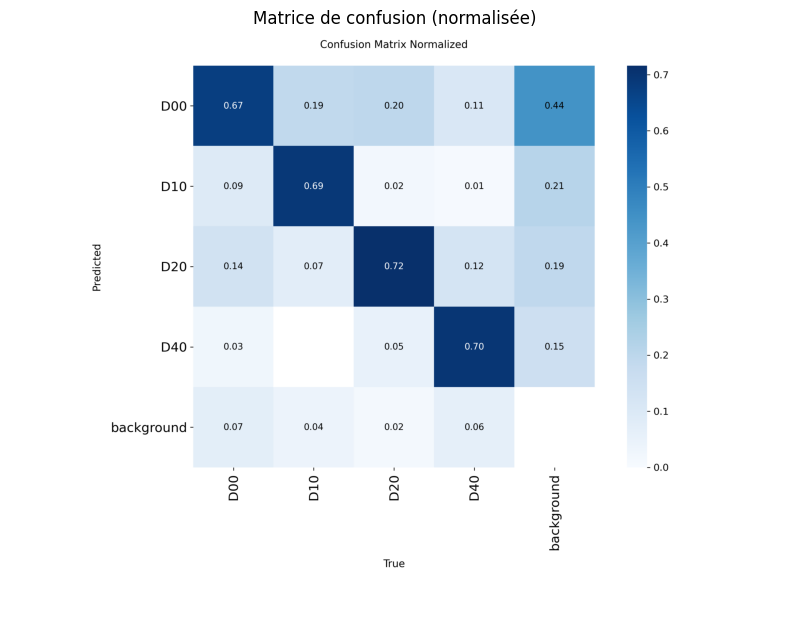

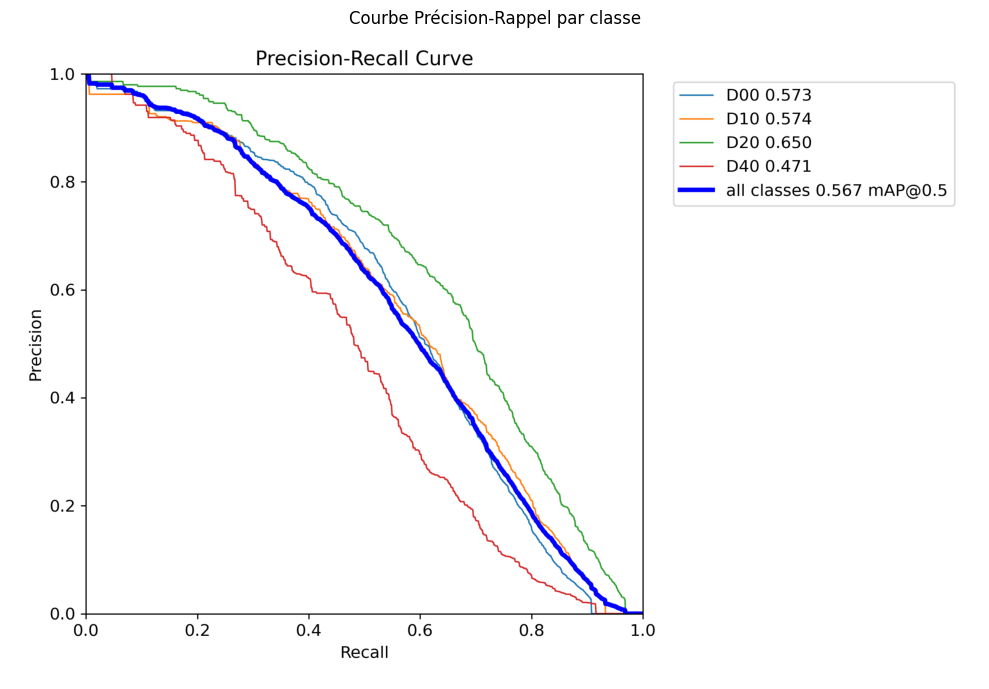

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# --- Dossier de l'entraînement baseline ---
RUN_DIR = Path("/content/drive/MyDrive/Datasets/RDD2022_runs/yolov8s_baseline")

# --- 1. Courbes principales générées par YOLO (results.png) ---
courbes = RUN_DIR / "results.png"
if courbes.exists():
    img = Image.open(courbes)
    plt.figure(figsize=(14, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Courbes d'entraînement — baseline 20 époques / 640px")
    plt.tight_layout()
    plt.show()
else:
    print(f"Fichier introuvable : {courbes}")

# --- 2. Matrice de confusion ---
confusion = RUN_DIR / "confusion_matrix_normalized.png"
if confusion.exists():
    img = Image.open(confusion)
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Matrice de confusion (normalisée)")
    plt.tight_layout()
    plt.show()

# --- 3. Courbe précision-rappel par classe ---
pr = RUN_DIR / "BoxPR_curve.png"
if pr.exists():
    img = Image.open(pr)
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Courbe Précision-Rappel par classe")
    plt.tight_layout()
    plt.show()

 epoch  box_loss  cls_loss  dfl_loss  precision  recall  mAP50  mAP50-95
     1    2.1310    2.6944    1.8579     0.3412  0.2299 0.1775    0.0671
     3    1.9944    2.3562    1.7516     0.3473  0.3497 0.2761    0.1152
     5    1.8975    2.1790    1.6749     0.4626  0.3906 0.3632    0.1603
     7    1.8281    2.0546    1.6194     0.5031  0.4143 0.4126    0.1866
     9    1.7890    1.9669    1.5893     0.5252  0.4398 0.4447    0.2044
    11    1.7684    1.8708    1.6208     0.5739  0.4533 0.4882    0.2311
    13    1.7257    1.7641    1.5882     0.5625  0.4884 0.5062    0.2458
    15    1.6906    1.6915    1.5636     0.5854  0.5002 0.5343    0.2664
    17    1.6548    1.6169    1.5363     0.6065  0.5108 0.5508    0.2767
    19    1.6165    1.5474    1.5090     0.6260  0.5166 0.5674    0.2877


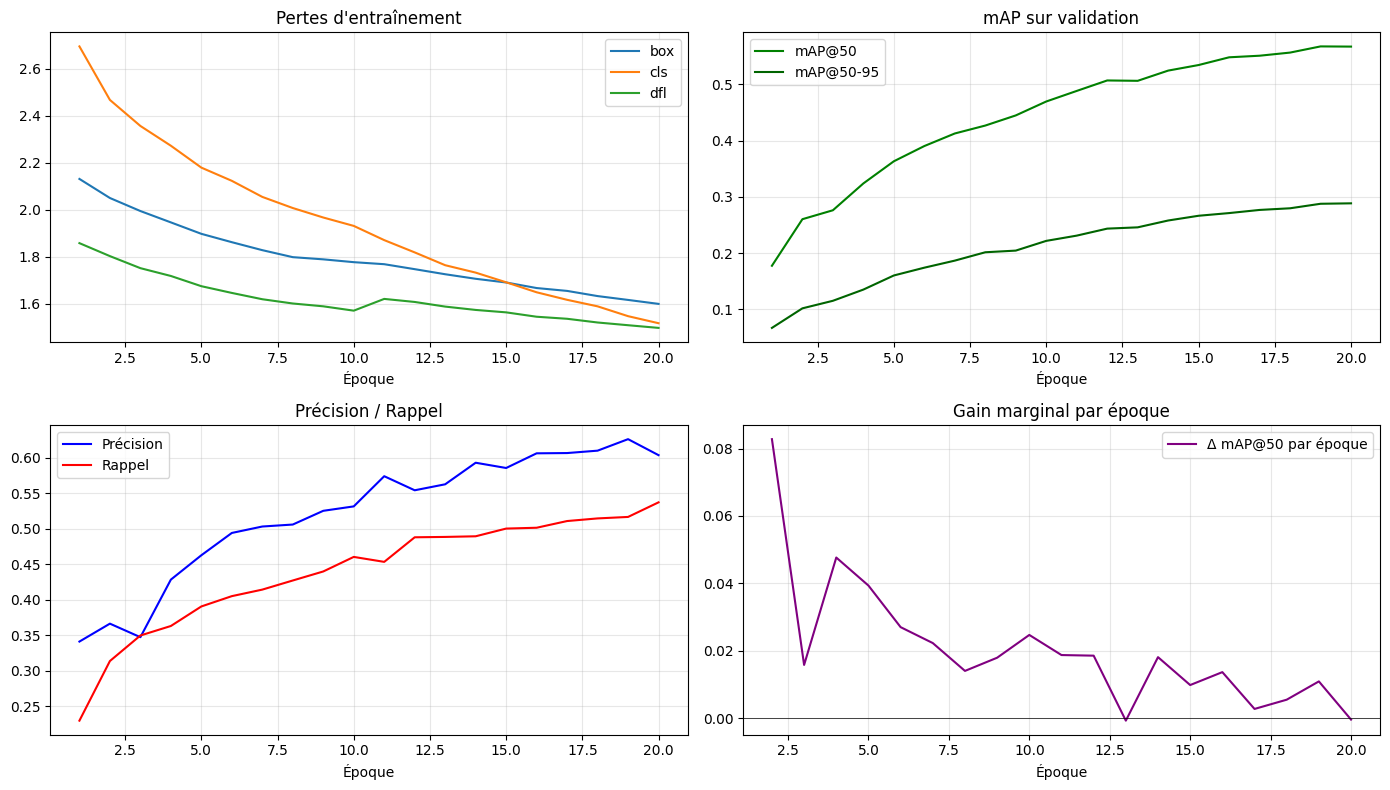

In [ ]:
# --- 4. Lecture des métriques brutes (results.csv) ---
import pandas as pd

csv_path = RUN_DIR / "results.csv"
if csv_path.exists():
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()  # nettoyage des espaces

    # Colonnes d'intérêt
    cols = ["epoch", "train/box_loss", "train/cls_loss", "train/dfl_loss",
            "metrics/precision(B)", "metrics/recall(B)",
            "metrics/mAP50(B)", "metrics/mAP50-95(B)"]

    df_aff = df[cols].copy()
    df_aff.columns = ["epoch", "box_loss", "cls_loss", "dfl_loss",
                      "precision", "recall", "mAP50", "mAP50-95"]

    # Affichage toutes les 2 époques
    print(df_aff.iloc[::2].round(4).to_string(index=False))

    # --- Graphique manuel ---
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    axes[0, 0].plot(df_aff["epoch"], df_aff["box_loss"], label="box")
    axes[0, 0].plot(df_aff["epoch"], df_aff["cls_loss"], label="cls")
    axes[0, 0].plot(df_aff["epoch"], df_aff["dfl_loss"], label="dfl")
    axes[0, 0].set_title("Pertes d'entraînement")
    axes[0, 0].set_xlabel("Époque")
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)

    axes[0, 1].plot(df_aff["epoch"], df_aff["mAP50"], label="mAP@50", color="green")
    axes[0, 1].plot(df_aff["epoch"], df_aff["mAP50-95"], label="mAP@50-95", color="darkgreen")
    axes[0, 1].set_title("mAP sur validation")
    axes[0, 1].set_xlabel("Époque")
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)

    axes[1, 0].plot(df_aff["epoch"], df_aff["precision"], label="Précision", color="blue")
    axes[1, 0].plot(df_aff["epoch"], df_aff["recall"], label="Rappel", color="red")
    axes[1, 0].set_title("Précision / Rappel")
    axes[1, 0].set_xlabel("Époque")
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)

    axes[1, 1].plot(df_aff["epoch"], df_aff["mAP50"] - df_aff["mAP50"].shift(1),
                    label="Δ mAP@50 par époque", color="purple")
    axes[1, 1].axhline(0, color="black", linewidth=0.5)
    axes[1, 1].set_title("Gain marginal par époque")
    axes[1, 1].set_xlabel("Époque")
    axes[1, 1].legend()
    axes[1, 1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## 19. Phase A — Reprise avec cos_lr et patience

On repart des poids pré-entraînés COCO (pas du best.pt précédent, pour éviter
un biais du baseline). Entraînement à 640px, 25 époques, scheduler cosinus,
patience 10. Tout est sauvegardé dans le Drive : si Colab coupe, on reprendra.

In [ ]:
from ultralytics import YOLO

modele_A = YOLO("yolov8s.pt")

resultats_A = modele_A.train(
    data=str(chemin_yaml),
    epochs=25,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/content/drive/MyDrive/Datasets/RDD2022_runs",
    name="yolov8s_phaseA_640_25ep",
    exist_ok=True,
    pretrained=True,
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    cos_lr=True,
    patience=10,
    cls_pw=1.0,
    verbose=True,
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=1.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/datasets/RDD2022_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_phaseA_640_25ep, nbs=64, nms=None, opset=

## 20. Phase B — Reprise à résolution supérieure

On reprend depuis le meilleur checkpoint de la Phase A et on augmente la
résolution à 800px. Objectif : affiner la distinction entre D00, D10 et D20,
qui se confondaient à 640px. Le learning rate est réduit (fine-tuning).

In [ ]:
from ultralytics import YOLO
from pathlib import Path

best_A = Path("/content/drive/MyDrive/RDD2022_runs_local/yolov8s_phaseA_640_25ep/weights/best.pt")
if not best_A.exists():
    raise FileNotFoundError(f"Checkpoint introuvable : {best_A}")

print(f"Checkpoint : {best_A}")
print(f"Taille     : {best_A.stat().st_size / 1e6:.1f} Mo")

modele_B = YOLO(str(best_A))

resultats_B = modele_B.train(
    data=str(chemin_yaml),
    epochs=20,
    imgsz=800,
    batch=8,
    device=0,
    workers=2,
    project="/content/drive/MyDrive/RDD2022_runs_local",
    name="yolov8s_phaseB_800_20ep",
    exist_ok=True,
    pretrained=False,
    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.01,
    cos_lr=True,
    patience=10,
    cls_pw=0.5,
    verbose=True,
)

Checkpoint : /content/drive/MyDrive/RDD2022_runs_local/yolov8s_phaseA_640_25ep/weights/best.pt
Taille     : 22.5 Mo
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.5, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/datasets/RDD2022_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, m

## 21. Évaluation finale sur le test set

On évalue le meilleur modèle (Phase A) sur le split test, jamais utilisé ni
à l'entraînement ni à la validation. C'est la mesure de performance finale
à reporter dans le rapport.

In [ ]:
from ultralytics import YOLO
from pathlib import Path

best_final = Path("/content/drive/MyDrive/RDD2022_runs_local/yolov8s_phaseA_640_25ep/weights/best.pt")
if not best_final.exists():
    raise FileNotFoundError(f"Checkpoint introuvable : {best_final}")

modele_final = YOLO(str(best_final))

metriques = modele_final.val(
    data=str(chemin_yaml),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
)

CLASSES = ["D00", "D10", "D20", "D40"]

print(f"\n=== Résultats finaux (test set) ===")
print(f"mAP@50    : {metriques.box.map50:.4f}")
print(f"mAP@50-95 : {metriques.box.map:.4f}")
print(f"Précision : {metriques.box.mp:.4f}")
print(f"Rappel    : {metriques.box.mr:.4f}")
print()
for i, nom in enumerate(CLASSES):
    print(f"  {nom} : AP@50 = {metriques.box.ap50[i]:.4f} | AP@50-95 = {metriques.box.ap[i]:.4f}")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 24.2±13.7 MB/s, size: 70.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/datasets/RDD2022_yolo/China_Drone/test/labels... 2402 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2402/2402 507.5it/s 4.7s
val: New cache created: /content/datasets/RDD2022_yolo/China_Drone/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 151/151 2.7it/s 55.6s
                   all       2402       5716      0.646      0.573      0.622      0.329
                   D00       1384       2745       0.62      0.551      0.582      0.322
                   D10        773       1213      0

## 22. MLflow — Tracking

Exigence MLOps : tracer hyperparamètres, métriques et artefacts du modèle final.
On installe MLflow, on logue le run Phase A (le modèle retenu) et on stocke
les artefacts dans le Drive.

In [ ]:
!pip install -q mlflow

import mlflow
from pathlib import Path

# --- Configuration MLflow ---
MLFLOW_DIR = Path("/content/drive/MyDrive/RDD2022_runs_local/mlruns")
MLFLOW_DIR.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(f"file://{MLFLOW_DIR}")
mlflow.set_experiment("rdd2022_crack_detection")

# --- Log du run final ---
with mlflow.start_run(run_name="phaseA_yolov8s_640_25ep"):
    # Hyperparamètres
    mlflow.log_params({
        "modele": "yolov8s",
        "imgsz": 640,
        "epochs": 25,
        "batch": 16,
        "optimizer": "AdamW",
        "lr0": 0.001,
        "cos_lr": True,
        "cls_pw": 1.0,
        "dataset": "RDD2022 (7 pays)",
        "nb_train_images": 19000,
        "nb_val_images": 2365,
        "nb_test_images": 2402,
    })

    # Métriques du test set
    mlflow.log_metrics({
        "test_mAP50":    float(metriques.box.map50),
        "test_mAP50_95": float(metriques.box.map),
        "test_precision": float(metriques.box.mp),
        "test_recall":    float(metriques.box.mr),
        "test_AP50_D00": float(metriques.box.ap50[0]),
        "test_AP50_D10": float(metriques.box.ap50[1]),
        "test_AP50_D20": float(metriques.box.ap50[2]),
        "test_AP50_D40": float(metriques.box.ap50[3]),
    })

    # Artefacts
    mlflow.log_artifact(str(best_final), artifact_path="modele")
    mlflow.log_artifact(str(chemin_yaml), artifact_path="config")

    # Courbes du run (si présentes)
    run_dir = best_final.parent.parent
    for nom in ["results.png", "confusion_matrix_normalized.png", "BoxPR_curve.png"]:
        p = run_dir / nom
        if p.exists():
            mlflow.log_artifact(str(p), artifact_path="courbes")

print("Run MLflow enregistré.")
print(f"Pour consulter : mlflow ui --backend-store-uri file://{MLFLOW_DIR}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 509.1 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 39.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 73.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 73.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

MlflowException: The filesystem tracking backend (e.g., './mlruns') is in maintenance mode and will not receive further updates. Please migrate to a database backend (e.g., 'sqlite:///mlflow.db') to access the latest MLflow features. The `mlflow migrate-filestore` tool migrates your existing data losslessly. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance. If the filesystem backend is required for your workflow, set `MLFLOW_ALLOW_FILE_STORE=true` to opt out of this exception.

In [21]:
from pathlib import Path

gitignore_content = """
# Données lourdes
*.zip
*.part
datasets/
RDD2022_split/
RDD2022_yolo/
RDD2022_local/
RDD2022_runs_local/

# Environnements
.venv/
venv/
env/

# Python
__pycache__/
*.py[cod]
*.egg-info/
.pytest_cache/
.ipynb_checkpoints/

# Modèles lourds
*.pt
*.pth
*.ckpt
*.onnx

# MLflow
mlruns/
mlflow.db

# DVC
.dvc/cache/
.dvc/tmp/

# Système
.DS_Store
Thumbs.db

# Éditeurs
.vscode/
.idea/
"""

Path("/content/.gitignore").write_text(gitignore_content.strip())
print("Gitignore créé.")
print(Path("/content/.gitignore").read_text())

Gitignore créé.
# Données lourdes
*.zip
*.part
datasets/
RDD2022_split/
RDD2022_yolo/
RDD2022_local/
RDD2022_runs_local/

# Environnements
.venv/
venv/
env/

# Python
__pycache__/
*.py[cod]
*.egg-info/
.pytest_cache/
.ipynb_checkpoints/

# Modèles lourds
*.pt
*.pth
*.ckpt
*.onnx

# MLflow
mlruns/
mlflow.db

# DVC
.dvc/cache/
.dvc/tmp/

# Système
.DS_Store
Thumbs.db

# Éditeurs
.vscode/
.idea/


In [22]:
import subprocess

# --- Configuration Git (remplace par tes infos GitHub) ---
EMAIL = "plamedimatondomtd@gmail.com"
USERNAME = "MTD-MTD"

subprocess.run(["git", "config", "--global", "user.email", EMAIL], check=True)
subprocess.run(["git", "config", "--global", "user.name", USERNAME], check=True)
print(f"Git configuré : {USERNAME} <{EMAIL}>")

# --- Cloner le repo GitHub ---
REPO_URL = "https://github.com/MTD-MTD/TI_Exam.git"
CHEMIN_REPO = "/content/TI_Exam"

# Si le dossier existe déjà, on le supprime pour repartir propre
import shutil
if Path(CHEMIN_REPO).exists():
    shutil.rmtree(CHEMIN_REPO)

subprocess.run(["git", "clone", REPO_URL, CHEMIN_REPO], check=True)
print(f"Repo cloné dans {CHEMIN_REPO}")

Git configuré : MTD-MTD <plamedimatondomtd@gmail.com>
Repo cloné dans /content/TI_Exam
